# 1. Doppia fenditura: misura della lunghezza d'onda del laser



### Obiettivi
Misurare la distanza tra due massimi consecutivi, calcolare la lunghezza d'onda del laser e il suo errore, confrontare il risultato con il valore nominale del manuale.


## 2. Fotografia dell'apparato

![alt text](EFBE0B0E-9F82-4B61-8027-135E0947B8EF_1_102_o.jpeg)

![alt text](1170904D-6E0F-4D03-A48D-61B6284A385D_1_102_o.jpeg)

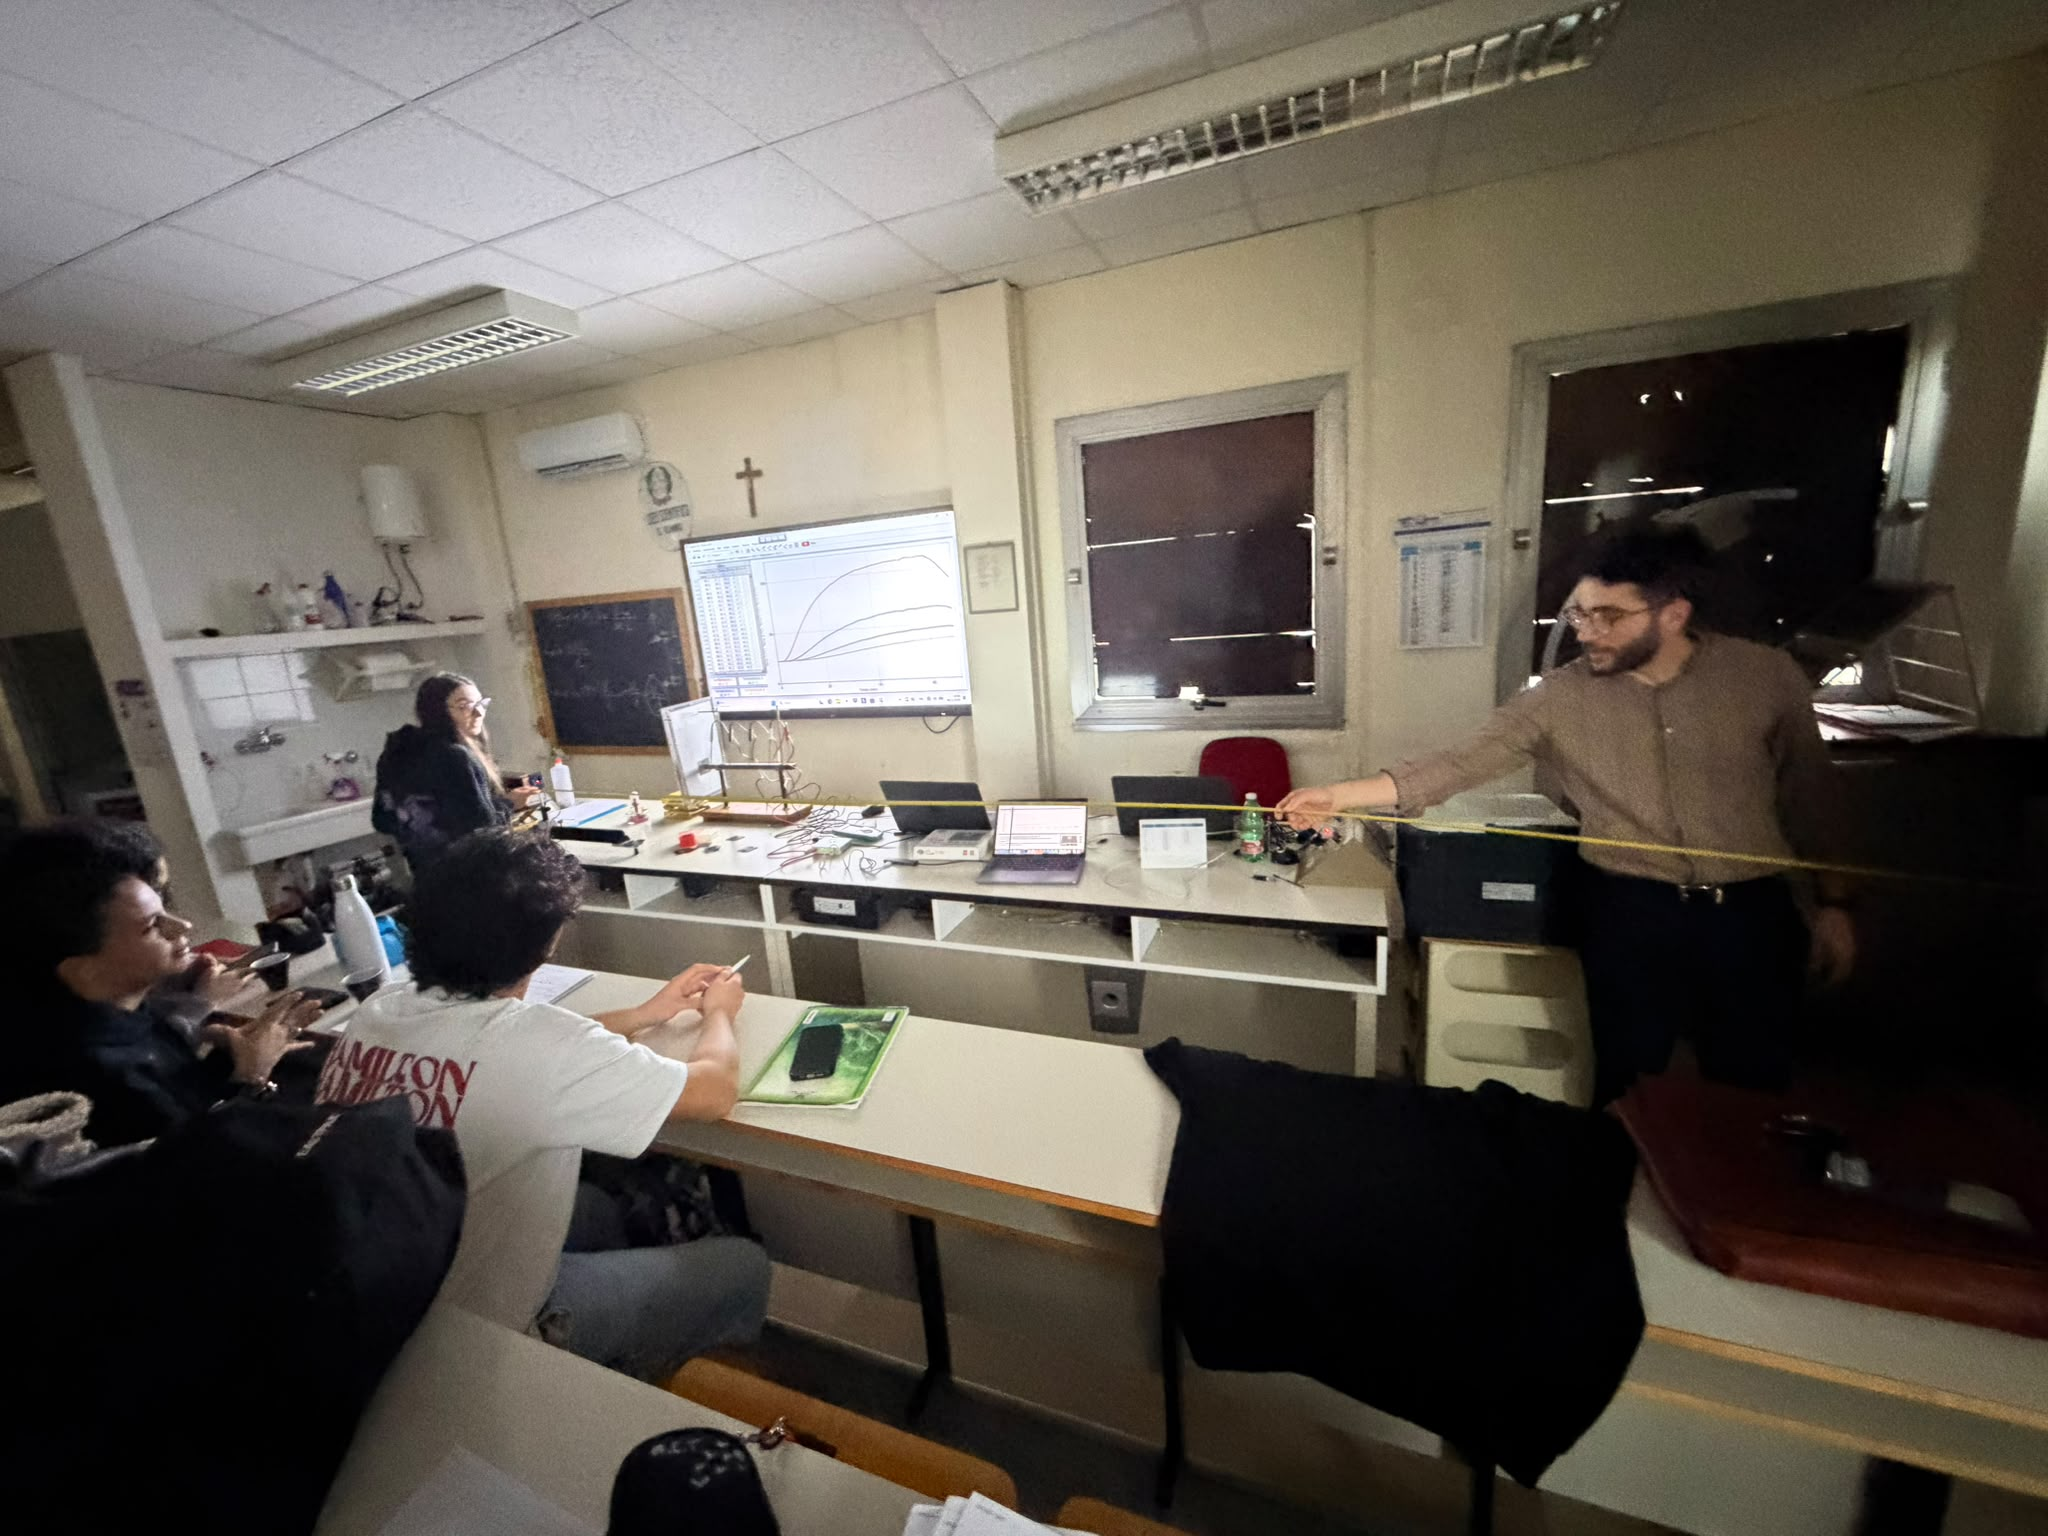

![alt text](891D27F7-4077-43F4-86CE-E0B08CFE82BE_1_102_o.jpeg)

## 3. Descrizione e procedura sperimentale

La luce del laser attraversa due fenditure e forma sullo schermo una successione di frange luminose e scure. Nel nostro esperimento erano distinguibili pochi massimi, quindi abbiamo misurato la distanza tra **due massimi consecutivi**.

Indichiamo con:
- $i$ la distanza tra i due massimi, detta **interfrangia**;
- $d$ la distanza tra i centri delle fenditure;
- $L$ la distanza tra le fenditure e lo schermo;
- $\lambda$ la lunghezza d'onda del laser.

Con l'apparato ben allineato, lo schermo sufficientemente lontano e per piccoli angoli, cioè osservando frange vicine all'asse, vale:

$$i=\frac{\lambda L}{d}.$$

In questa approssimazione la distanza tra massimi consecutivi non dipende dall'ordine. Ricaviamo quindi:

$$\boxed{\lambda=\frac{i\,d}{L}}.$$

### Procedura
1. Sistemare laser, fenditure e schermo. Non guardare il fascio diretto o riflesso.
2. Misurare $L$ e annotare $d$, specificando se è misurata o fornita con le fenditure.
3. Misurare la distanza $i$ tra i centri di due massimi consecutivi. Assicurarsi che non ci sia un altro massimo tra i due.
4. Assegnare un errore a ogni lunghezza, considerando lo strumento e la difficoltà della lettura.
5. Calcolare $\lambda$, il suo errore e confrontare il risultato con il manuale del laser.

## 4. Acquisizione dati

Inserire le lunghezze e i rispettivi **errori assoluti**, indicati con $\Delta$. Qui usiamo gli errori come limiti stimati, secondo la semplice regola scolastica della somma degli errori relativi.

| Grandezza | Valore misurato | Errore assoluto |
|---|---|---|
| Interfrangia $i$ | … mm | … mm |
| Distanza tra fenditure $d$ | … mm | … mm |
| Distanza dallo schermo $L$ | … m | … m |

Valore nominale del laser: … nm. Manuale, pagina: …

Se avete letto due posizioni sul righello, calcolate prima:
$$i=x_2-x_1,\qquad \Delta i=\Delta x_1+\Delta x_2.$$
Se invece avete misurato direttamente la distanza, inserite la sua stima di errore. Non applicate entrambe le procedure alla stessa misura.

In [3]:
# DATI SINTETICI DI ESEMPIO: sostituire con le misure del gruppo.
# Tutte le lunghezze utilizzate nel calcolo sono espresse in metri.

i = 6e-3          # interfrangia: 6 mm
errore_i = 2e-3   # errore sull'interfrangia: 2 mm

d = 0.50e-3        # distanza tra le fenditure: 0,500 mm
errore_d = 0.01e-3  # errore su d: 0,01 mm

L = 4.691           # distanza fenditure-schermo: 4.691 m
errore_L = 0.001     # errore su L: 0,005 m

lambda_nominale = 633  # nm: esempio, sostituire con il valore del manuale

## 5. Analisi Python

### Lunghezza d'onda ed errore
Calcoliamo prima la lunghezza d'onda:
$$\lambda=\frac{i\,d}{L}.$$

Per un prodotto e un quoziente sommiamo gli errori relativi:
$$\frac{\Delta\lambda}{\lambda}\simeq
\frac{\Delta i}{i}+\frac{\Delta d}{d}+\frac{\Delta L}{L}.$$

L'errore assoluto è quindi:
$$\boxed{\Delta\lambda\simeq\lambda\left(
\frac{\Delta i}{i}+\frac{\Delta d}{d}+\frac{\Delta L}{L}\right)}.$$

È una stima approssimata, adatta a errori piccoli rispetto alle misure. Non descrive gli errori dovuti, per esempio, a un cattivo allineamento o alla scelta di massimi non consecutivi.

In [4]:
# Controlli essenziali sui dati.
assert i > 0 and d > 0 and L > 0, "Le lunghezze devono essere positive."
assert 0 <= errore_i < i, "Controllare l'errore su i."
assert 0 <= errore_d < d, "Controllare l'errore su d."
assert 0 <= errore_L < L, "Controllare l'errore su L."

lunghezza_onda = i * d / L
errore_relativo = errore_i / i + errore_d / d + errore_L / L
errore_lambda = lunghezza_onda * errore_relativo

# Conversione da metri a nanometri: 1 m = 10^9 nm.
lambda_nm = lunghezza_onda * 1e9
errore_nm = errore_lambda * 1e9

print(f"Lunghezza d'onda = {lambda_nm:.1f} nm")
print(f"Errore assoluto = {errore_nm:.1f} nm")
print(f"Errore relativo percentuale = {errore_relativo * 100:.1f}%")
print(f"Risultato arrotondato: lambda = ({lambda_nm:.0f} ± {errore_nm:.0f}) nm")

Lunghezza d'onda = 639.5 nm
Errore assoluto = 226.1 nm
Errore relativo percentuale = 35.4%
Risultato arrotondato: lambda = (640 ± 226) nm


### Confronto con il manuale
Calcoliamo la differenza in valore assoluto tra la misura e il nominale. Controlliamo poi se il nominale cade nell'intervallo:

$$[\lambda-\Delta\lambda,\;\lambda+\Delta\lambda].$$

Questo è un semplice confronto con il nominale, non una prova che la misura sia esatta. Se il manuale riporta anche una tolleranza, occorre considerare anche quella. Lo scarto percentuale dal nominale è diverso dall'errore percentuale della misura.

In [5]:
assert lambda_nominale > 0, "Il valore nominale deve essere positivo."

scarto = abs(lambda_nm - lambda_nominale)
minimo = lambda_nm - errore_nm
massimo = lambda_nm + errore_nm

print(f"Valore nominale = {lambda_nominale:.1f} nm")
print(f"Scarto assoluto = {scarto:.1f} nm")
print(f"Scarto percentuale = {100 * scarto / lambda_nominale:.2f}%")
print(f"Intervallo della misura: da {minimo:.1f} a {massimo:.1f} nm")

if minimo <= lambda_nominale <= massimo:
    print("Il valore nominale rientra nell'intervallo della misura.")
else:
    print("Il valore nominale non rientra nell'intervallo della misura.")

Valore nominale = 633.0 nm
Scarto assoluto = 6.5 nm
Scarto percentuale = 1.03%
Intervallo della misura: da 413.4 a 865.6 nm
Il valore nominale rientra nell'intervallo della misura.


### Conclusioni
Abbiamo misurato la distanza tra due massimi consecutivi e ottenuto:

$$\lambda=(\ldots\pm\ldots)\ \mathrm{nm}.$$

Il manuale riporta … nm. Il nominale … nell'intervallo della misura. Le principali difficoltà sperimentali sono state … . Per migliorare la misura potremmo … .

**Con i dati sintetici** si ottiene circa $(633\pm48)$ nm. Questi numeri servono solo a mostrare il funzionamento del notebook: le conclusioni dell'esperimento vanno scritte usando le misure reali.

### Domande
1. Perché non serve conoscere l'ordine dei due massimi?
2. Che cosa succederebbe se i massimi scelti non fossero consecutivi?
3. Quale dei tre errori relativi contribuisce maggiormente all'errore finale?
4. Come cambierebbe l'interfrangia allontanando lo schermo?